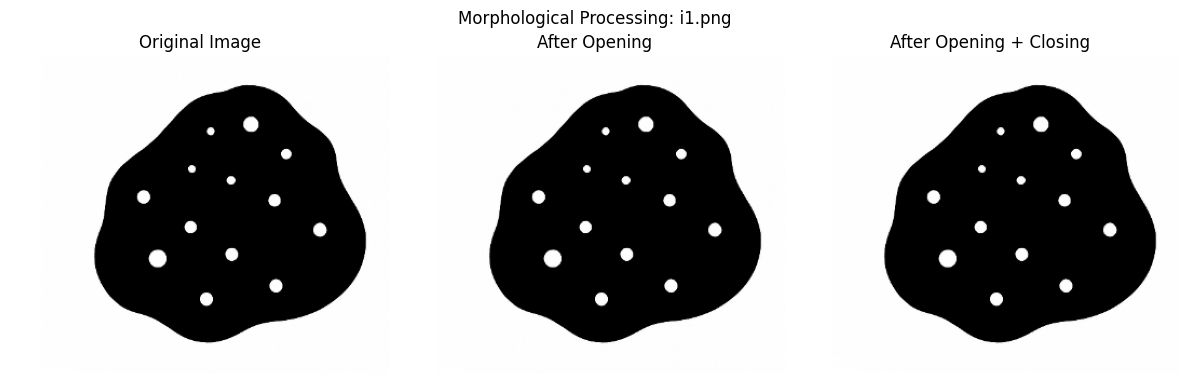

Processed: i1.png
Saved to: Morphology_Results\i1.png


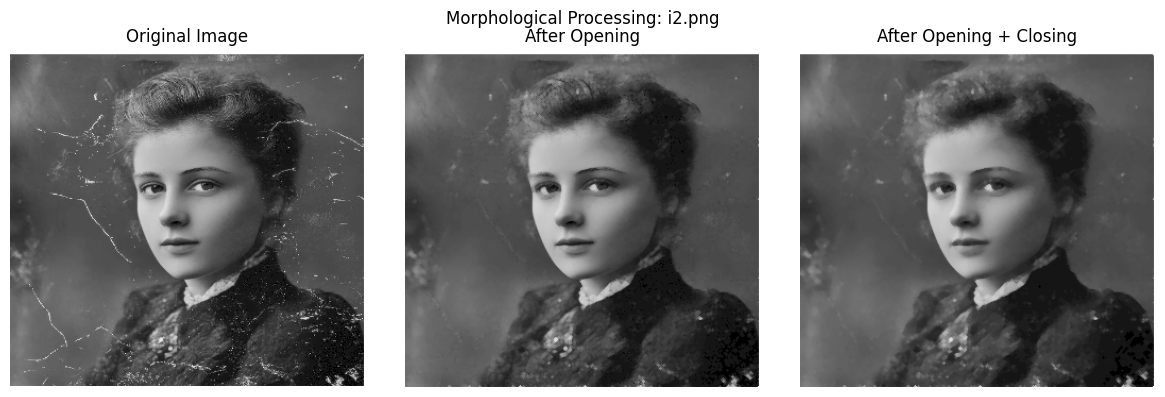

Processed: i2.png
Saved to: Morphology_Results\i2.png


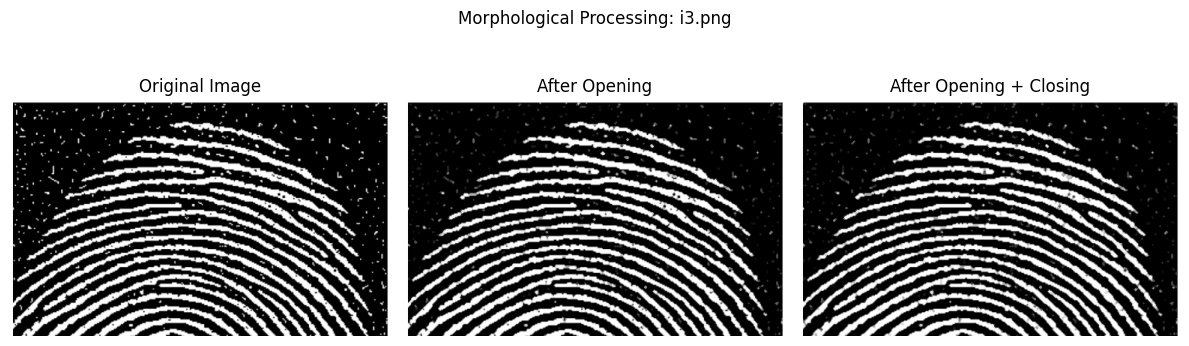

Processed: i3.png
Saved to: Morphology_Results\i3.png
All images processed.


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Image paths
image_paths = ["i1.png", "i2.png", "i3.png"]

# Structuring element
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

# Output folder
output_dir = Path("Morphology_Results")
output_dir.mkdir(exist_ok=True)

for file in image_paths:

    image = cv2.imread(file, cv2.IMREAD_GRAYSCALE)

    if image is None:
        print(f"Image not found: {file}")
        continue

    # Step 1: Remove small bright noise using opening
    opening = cv2.morphologyEx(
        image, cv2.MORPH_OPEN, kernel
    )

    # Step 2: Fill narrow dark cracks using closing
    result = cv2.morphologyEx(
        opening, cv2.MORPH_CLOSE, kernel
    )

    # Display results
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(image, cmap="gray", vmin=0, vmax=255)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(opening, cmap="gray", vmin=0, vmax=255)
    plt.title("After Opening")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(result, cmap="gray", vmin=0, vmax=255)
    plt.title("After Opening + Closing")
    plt.axis("off")

    plt.suptitle(f"Morphological Processing: {file}")
    plt.tight_layout()
    plt.show()

    # Save output
    output_path = output_dir / file
    cv2.imwrite(str(output_path), result)

    print(f"Processed: {file}")
    print(f"Saved to: {output_path}")

print("All images processed.")